# What is a pixel?
Exploring images as arrays of numbers with OpenCV.

**Setup** (once, in the VS Code terminal, with the same interpreter as the notebook):<br>
`python -m pip install opencv-python matplotlib`

In [1]:
import cv2
import matplotlib.pyplot as plt

## 1. Load an image and inspect it

In [2]:
img = cv2.imread('my_image.jpg')            # an image = an array of numbers
print(type(img))                            # numpy.ndarray
print(img.shape, img.dtype, img.min(), img.max())
print(img[100, 200])                        # one pixel = 3 values [B, G, R]

<class 'numpy.ndarray'>
(724, 1086, 3) uint8 0 255
[24 28 33]


### • What does cv2.imread return? What is its shape, dtype, min/max values?

`cv2.imread` returns a **NumPy array** (`numpy.ndarray`), or `None` if the file cannot be read (no error is raised).

Output: `(724, 1086, 3) uint8 0 255`

**`(724, 1086, 3)`**: the image is loaded as a 3D array: 724 rows × 1086 columns, and each pixel has 3 channels (B, G, R), so it is stored as a colour image.<br>
Note: `cv2.imread` loads every image with 3 channels by default, even a grayscale one.

**`uint8`**: each value is an 8-bit integer.

**`0 255`** (min, max): the image uses the full possible range, from pure black to maximum intensity.

### • What does uint8 mean?

`uint8` stands for *unsigned integer on 8 bits*:

- **integer**: whole numbers only (24, 28, 33…, never 24.5)
- **unsigned**: no negative numbers
- **8 bits**: each value is stored in 8 binary digits (0 or 1), i.e. 1 byte. 8 bits give 2⁸ = 256 combinations, hence values from 0 to 255.

`00000000` = 0 (black)<br>
`00011000` = 24 (our pixel, blue channel)<br>
`11111111` = 255 (maximum intensity)

**Practical consequences:**

- **Memory**: the image takes 724 × 1086 × 3 ≈ 2.4 million bytes, i.e. about 2.4 MB in memory.
- **Overflow**: 255 + 1 does not give 256 but 0, because the counter wraps around. This is why `cv2.add()`, which caps values at 255, is used to brighten an image.

In [3]:
import numpy as np
print(np.uint8(255) + np.uint8(1))                          # 0   -> overflow
print(cv2.add(np.array([[255]], np.uint8), np.array([[1]], np.uint8))[0, 0])   # 255 -> saturation

0
255


/var/folders/4m/jbzcgm115rbdm2hwhvzwyt640000gn/T/ipykernel_49886/3150626296.py:2: RuntimeWarning: overflow encountered in scalar add
  print(np.uint8(255) + np.uint8(1))                          # 0   -> overflow


### • What does (H, W, 3) mean?

Standard notation for the shape of a colour image:

- **H** = **Height**, the number of rows of pixels (724 here)
- **W** = **Width**, the number of columns of pixels (1086 here)
- **3** = the number of **channels**: three intensity values per pixel (B, G, R in OpenCV)

Height comes first because arrays are indexed row by row: `img[y, x]` = `img[row, column]`.<br>
A grayscale image has only one value per pixel, so its shape is just `(H, W)`.

In [4]:
H, W, C = img.shape
print(f"Height = {H}, Width = {W}, Channels = {C}, Pixels = {H * W:,}")

Height = 724, Width = 1086, Channels = 3, Pixels = 786,264


### • In what order does OpenCV store channels?

OpenCV stores colour channels in **BGR** order (Blue, Green, Red), not RGB.<br>
For our pixel `[24 28 33]`: B = 24, G = 28, R = 33.

Consequence: before displaying an OpenCV image with matplotlib (which expects RGB), it must be converted with `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`; otherwise red and blue are swapped.

Sources: OpenCV tutorial [Basic Operations on Images](https://docs.opencv.org/4.x/d3/df2/tutorial_py_basic_ops.html) · API reference [imgcodecs](https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html)

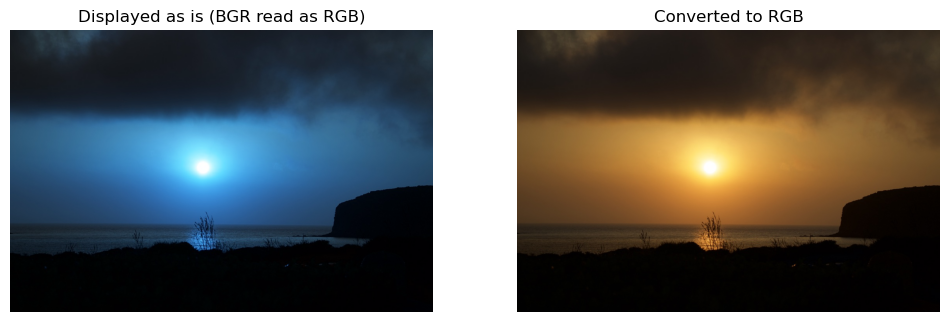

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(img);                                  ax[0].set_title("Displayed as is (BGR read as RGB)")
ax[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[1].set_title("Converted to RGB")
for a in ax: a.axis("off")
plt.show()

## 2. Access a single pixel

### • How to access pixel (100, 200)? What does it contain?

**Access:** `img[100, 200]`, indexed as `img[row, column]` = `img[y, x]`: row 100 (from the top), column 200 (from the left). Indexing starts at 0.

**Content:** `[24 28 33]`, an array of 3 `uint8` values in **BGR** order:
- B = 24
- G = 28
- R = 33

Low and similar values on all three channels → a very dark grey, almost black, with a slight red tint.

A single channel can be read directly: `img[100, 200, 2]` → 33 (red).

Watch the order: `img[100, 200]` is the point (x = 200, y = 100). OpenCV drawing functions such as `cv2.circle` take coordinates as `(x, y)`.

In [6]:
px = img[100, 200]
b, g, r = px
print(px, "-> B =", b, " G =", g, " R =", r)
print("Red channel only:", img[100, 200, 2])

[24 28 33] -> B = 24  G = 28  R = 33
Red channel only: 33


## 3. See the pixels

Zoom on a 20 × 20 pixel area. `interpolation="nearest"` keeps each pixel as a crisp square: each square = one pixel = one colour.

In a notebook, use `plt.imshow` rather than `cv2.imshow`: `cv2.imshow` opens a separate window and `cv2.waitKey(0)` freezes the cell until a key is pressed in that window.

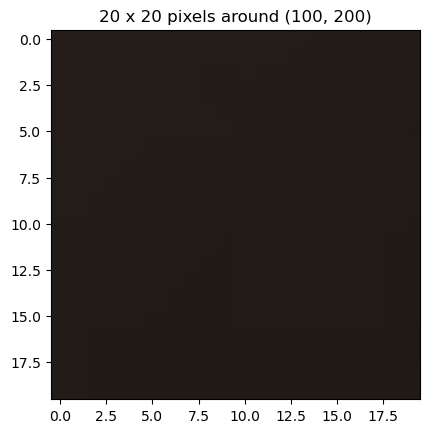

In [7]:
zone = img[90:110, 190:210]
plt.imshow(cv2.cvtColor(zone, cv2.COLOR_BGR2RGB), interpolation="nearest")
plt.title("20 x 20 pixels around (100, 200)")
plt.show()

## 4. Modify pixels

Modifying a pixel = changing its 3 numbers. A single pixel out of ~786,000 is invisible at full size, so we colour a small area to see the change.

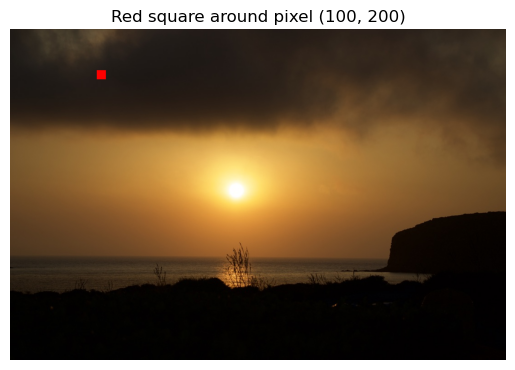

In [8]:
mod = img.copy()
mod[100, 200] = [0, 0, 255]           # one pixel -> pure red (B=0, G=0, R=255)
mod[90:110, 190:210] = [0, 0, 255]    # a 20 x 20 area -> visible
plt.imshow(cv2.cvtColor(mod, cv2.COLOR_BGR2RGB))
plt.title("Red square around pixel (100, 200)")
plt.axis("off")
plt.show()

## Conclusion

A pixel is a sample of light, stored as 1 number (grayscale) or 3 numbers (B, G, R) between 0 and 255, at a position (row, column) in an array. All image analysis, including motion detection, comes down to computations on these arrays.

In [ ]:
1.3 Bit Depth
Questions to investigate
• What does 8 bits mean? 24 bits?


• How many levels in 8-bit grayscale?


• How many colors in 24-bit RGB? (8-bit per channel)


• What happens if you convert to float?

Manipulations
cv2 . C O L O R _ B G R 2 G R A Y )
gray . min () , gray . max () )
1 gray = cv2 . cvtColor ( img , 2 print ( gray . dtype , 3
4 img_float = img . astype ( np . float32 ) / 255.0
5 print ( img_float . dtype , img_float . min () , img_float . max () )

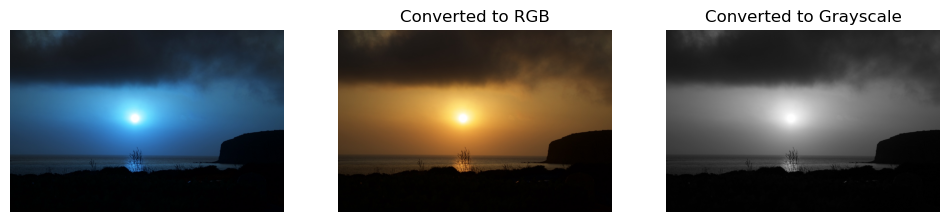

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img);
ax[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[1].set_title("Converted to RGB")
# and now in gray
ax[2].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cmap="gray"); ax[2].set_title("Converted to Grayscale")
for a in ax: a.axis("off")
plt.show()

In [17]:
cv2 . cvtColor ( img , cv2 . COLOR _ B G R 2 G R A Y )
gray . min () , gray . max ()
1 gray = cv2 . cvtColor ( img , cv2 . COLOR _ B G R 2 G R A Y )
2 print ( gray . dtype , gray . min () , gray . max () )

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1854999887.py, line 1)